# kospi-charter 마스터 노트북 — 최근 1년 사업보고서 목록 + 코스피 정관 원문

이 노트북 하나를 위에서 아래로 실행하면 결과물 전체가 다시 만들어진다. 각 단계는 `scripts/sNN_*.py` 의 `main()` 을 부른다
(터미널에서 `python scripts/s01_list.py` … 로 돌려도 결과는 같다).

| 단계 | 하는 일 | 출처 |
|---|---|---|
| s01 | 최근 1년 사업보고서 목록, **최종보고서만** (`final=True` = `last_reprt_at=Y`) | OpenDART `list.json` (A001) |
| s02 | 소속시장 — **기준일 현재 상장사 목록 한 번** | KIND 상장종목현황 |
| s02b | KIND 코스피 상장회사 중 목록에 없는 회사와 근거 (사업보고서 이력·대신 낸 공시) | OpenDART `list.json`·`company.json` · KIND 공시 상세검색 |
| s03 | `[첨부정정]` 행의 `rcept_no_new` + 코스피 행의 첨부문서 목록 | DART `main.do` (`family`·`att` 선택상자) |
| s04 | 코스피 행의 정관 원문(텍스트·스캔 이미지) 내려받기·정리 | DART `viewer.do`·`download.do` |
| s04b | 스캔 이미지 정관 글자 인식(OCR) → `charter_ocr.txt` | Windows 내장 OCR (네트워크 없음) |
| s04c | PDF 로 첨부된 정관 → PDF 받기·글자 뽑기 → `charter_pdf.txt` | DART `download.do` · PyMuPDF |
| s04d | 스캔 쪽 전부를 Claude Opus 5.5 로 전사 → `charter_llm.txt` (비용 발생, 기본은 정리만) | Anthropic Message Batches API |
| s05 | 코스피 행마다 원본 제출일 ~ 기준일 주주총회소집공고(최종본) 목록 | OpenDART `list.json` (E006) |
| s06 | 소집공고 XML 원문 저장 → '정관의 변경' 절 찾기·txt 저장 | OpenDART `document.xml` |
| s07 | 결과물(JSON·CSV·XLSX) 만들기 | — |
| s08 | 웹페이지 데이터 `site/data.js` | — |

**재현성.** 기준일 `AS_OF` 를 고정한다(아래 설정 셀). 원본 응답(목록 페이지·KIND 목록·DART 화면·원문 HTML)은 모두
`data/raw/`·`data/charter/` 에 저장되고, 다시 실행하면 저장된 것을 읽는다. 처음부터 다시 받으려면 `data/raw` 를 지운다.
DART 는 IP 단위로 막으므로 **다른 DART 수집과 동시에 돌리지 않는다** (요청 간격 1초).


## 0. 환경

In [1]:
# 처음 한 번 (Colab 등 새 환경):
# !pip install -r ../requirements.txt
import os, sys, json
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "scripts"))

os.environ.setdefault("KC_AS_OF", "2026-11-16")   # 기준일 — 바꾸면 data/raw 를 지우고 다시 받는다
import pandas as pd
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 60)

import _common as C
print("ROOT", ROOT)
print("기준일", C.AS_OF, "· 조회기간", C.BGN, "~", C.AS_OF)
print("DART 키", len(C.dart_keys()), "개 (.env 또는 환경변수 DART_API_KEY*)")

ROOT C:\Users\Peter\github\case-projects\kospi-charter
기준일 2026-11-16 · 조회기간 2025-11-16 ~ 2026-11-16
DART 키 11 개 (.env 또는 환경변수 DART_API_KEY*)


## 1. 사업보고서 목록 (s01)

* `pblntf_detail_ty=A001`, `last_reprt_at=Y` — 보고서마다 **최종본 한 줄**
* 회사를 지정하지 않으면 검색기간이 3개월로 묶여 있어 3개월 이하 구간으로 나눠 부른다
* A001 안의 `사업보고서제출기한연장신고서` 는 뺀다
* 한 회사가 기간 안에 여러 번 냈으면 **가장 최근 것 하나만** — 결산기(`report_period`)가 가장 늦은 것, 같으면 접수번호가 늦은 것
  (뺀 행: `logs/s01_dropped_older.csv`)
* **사업연도**(`fiscal_year`)·**결산월**(`settle_month`)은 보고서명 `(YYYY.MM)` 에서 읽는다.
  사업연도는 OpenDART 정기보고서 API 의 `bsns_year` 와 같은 규칙(결산기 말일이 속한 연도)이다 — `docs/03-검증기록.md`

In [2]:
import s01_list
reports = pd.DataFrame(s01_list.main())
reports.head(3)

조회기간 2025-11-16 ~ 2026-11-16 (기준일 2026-11-16), 최종보고서만
  2025-11-16 ~ 2026-02-15  page 1/1  (구간 69건)


  2026-02-16 ~ 2026-05-15  page 1/32  (구간 3108건)


  2026-02-16 ~ 2026-05-15  page 2/32  (구간 3108건)


  2026-02-16 ~ 2026-05-15  page 3/32  (구간 3108건)


  2026-02-16 ~ 2026-05-15  page 4/32  (구간 3108건)


  2026-02-16 ~ 2026-05-15  page 5/32  (구간 3108건)


... (31 outputs left out)

  2026-08-16 ~ 2026-11-15  page 1/1  (구간 65건)


API 행 3564 (중복 0) → 사업보고서 3504건, 제외(연장신고서 등) 60건


회사별 최근 1건만: 3349사 · 뺀 옛 보고서 155건 (logs/s01_dropped_older.csv) · 접수일 기준으로 골랐다면 달라졌을 회사 16사
  정정 접두어: {'(없음)': 2666, '[기재정정]': 536, '[첨부추가]': 61, '[첨부정정]': 86}
  corp_cls(현재 기준): {'K': 1784, 'Y': 825, 'E': 633, 'N': 107}
  사업연도: {2025: 3284, 2026: 65}


,corp_code,corp_name,stock_code,corp_cls,report_nm,rcept_no,flr_nm,rcept_dt,rm,amend_tag,form_nm,report_period,fiscal_year,settle_month
0,00155373,풍강,093380,K,사업보고서 (2025.08),20251117000158,풍강,20251117,연,,사업보고서,2025.08,2025,8
1,00168401,금비,008870,Y,사업보고서 (2025.09),20251215000379,금비,20251215,연,,사업보고서,2025.09,2025,9
2,00145914,인터엠,017250,K,[기재정정]사업보고서 (2025.09),20251217000580,인터엠,20251217,연,[기재정정],사업보고서,2025.09,2025,9


In [3]:
print(reports["amend_tag"].replace("", "(없음)").value_counts().to_string())
print(pd.crosstab(reports["fiscal_year"], reports["settle_month"]))

amend_tag
(없음)      2666
[기재정정]     536
[첨부정정]      86
[첨부추가]      61


settle_month  2   3   4   5   6   7   8   9   11    12
fiscal_year                                           
2025           0   0   0   0   0   0   1   5   2  3276
2026           3  26   4   4  23   3   2   0   0     0


## 2. 소속시장 (s02) — KIND 기준일 현재 목록 한 번

KIND 상장종목현황에서 기준일 현재 상장사 목록을 한 번 받아(유가·코스닥·코넥스, 주권·외국주권·리츠·투자회사·스팩·DR)
종목코드(없으면 회사명)로 맞춘다. 목록에 없으면 `기타`.

> **한계** — 제출 당시가 아니라 **기준일 현재** 시장이다. 제출 뒤 상장폐지·이전상장·신규상장된 회사는 현재 시장으로 분류된다
> (예: 한창 005110 은 2026-03-26 제출 때 유가증권시장 상장사였지만 지금은 `기타`). OpenDART `corp_cls` 도 현재 기준이라 두 값은 같다.

In [4]:
import s02_market
market = s02_market.main()
pd.Series({k: v["market"] for k, v in market.items()}).value_counts()

KIND 20261116 현재 상장 목록 2769사: {('코넥스', '주권'): 107, ('코스닥', '기업인수목적회사'): 70, ('코스닥', '외국주권'): 11, ('코스닥', '주권'): 1743, ('코스닥', '주식예탁증권'): 9, ('코스피', '부동산투자회사'): 23, ('코스피', '외국주권'): 1, ('코스피', '주권'): 801, ('코스피', '주식예탁증권'): 1, ('코스피', '투자회사'): 3}


소속시장(현재 기준): {'코스닥': 1784, '코스피': 825, '기타': 633, '코넥스': 107}
증권구분: {'주권': 2615, '-': 633, '기업인수목적회사': 57, '부동산투자회사': 23, '주식예탁증권': 9, '외국주권': 12}
매칭 방법: {'code': 2716, '-': 633}
corp_cls 와 다른 행 0건 → logs/s02_market_vs_corp_cls.csv


코스닥    1784
코스피     825
기타      633
코넥스     107
Name: count, dtype: int64

## 2b. 코스피인데 목록에 없는 회사 (s02b)

KIND 기준일 현재 코스피 상장회사 중 이 목록(최근 1년 사업보고서)에 행이 없는 회사를 골라 근거를 붙인다.
OpenDART 로 ① 사업보고서 전체 이력(1999~) ② 조회기간의 모든 공시 ③ 결산월을, KIND 로 ④ 조회기간 공시 ⑤ '기타신고사항' 본문 제목을 본다.
투자회사는 DART 사업보고서 대신 KIND '기타신고사항'으로 분기·결산 보고(영업보고서·자산운용보고서 게시, 감사보고서 제출 등)를 낸다
(사용자 확인 2026-11-16). 결과는 s07 이 `data/final/kospi_absent.*` 로, 웹페이지는 사업보고서·정관 표 위 안내로 보여 준다.

In [5]:
import s02b_kospi_absent
absent = s02b_kospi_absent.main()
pd.DataFrame(absent)[["stock_code", "corp_name", "sec_group", "listed_date", "n_annual_reports_all",
                      "n_annual_reports_window", "kind_misc_n", "reason_code", "reason"]]

KIND 20261116 코스피 829사 · 목록에 있음 825 · 없음 4


  0220W0 한화머시너리앤서비스홀딩스 [주권] 사업보고서 전체 0 · 기간 0 · 기간 DART 공시 31 · KIND 공시 38(기타신고사항 0) → new_listing
  415640 KB발해인프라 [투자회사] 사업보고서 전체 0 · 기간 0 · 기간 DART 공시 17 · KIND 공시 53(기타신고사항 28) → no_annual_report
  094800 맵스리얼티 [투자회사] 사업보고서 전체 0 · 기간 0 · 기간 DART 공시 11 · KIND 공시 42(기타신고사항 16) → no_annual_report


  088980 맥쿼리인프라 [투자회사] 사업보고서 전체 0 · 기간 0 · 기간 DART 공시 4 · KIND 공시 35(기타신고사항 24) → no_annual_report


  KIND 요약 2026-11-16 실패: KINDParseError


KIND 상장현황 요약 2026-11-13: 유가 회사 829사(DR 포함) · 종목 936개 · {'주권': {'companies': 801, 'issues': 908}, '외국주권': {'companies': 1, 'issues': 1}, '투자회사': {'companies': 3, 'issues': 3}, '부동산투자회사': {'companies': 23, 'issues': 23}, '소계': {'companies': 828, 'issues': 935}, '주식예탁증권(DR)': {'companies': 1, 'issues': 1}}
사유: {'new_listing': 1, 'no_annual_report': 3}


,stock_code,corp_name,sec_group,listed_date,n_annual_reports_all,n_annual_reports_window,kind_misc_n,reason_code,reason
0,0220W0,한화머시너리앤서비스홀딩스,주권,2026-08-25,0,0,0,new_listing,조회기간 안 신규상장(2026-08-25). 상장 뒤 낸 사업보고서 없음 · 결산월 12월 → 첫 사...
1,415640,KB발해인프라,투자회사,2024-11-29,0,0,28,no_annual_report,투자회사. DART 사업보고서 이력 없음(1999년 이후 0건). 대신 분기·결산 보고를 KIND '...
2,094800,맵스리얼티,투자회사,2007-04-09,0,0,16,no_annual_report,투자회사. DART 사업보고서 이력 없음(1999년 이후 0건). 대신 분기·결산 보고를 KIND '...
3,088980,맥쿼리인프라,투자회사,2006-03-15,0,0,24,no_annual_report,투자회사. DART 사업보고서 이력 없음(1999년 이후 0건). 대신 분기·결산 보고를 KIND '...


## 3. `rcept_no_new`·첨부문서 목록 (s03)

`[첨부정정]` 은 첨부서류만 바꾼 공시라 접수번호는 새로 받지만 본문이 없다. 기존 프로젝트(`get_recent`) 규칙 그대로
DART `main.do` 의 `<select id="family">`(+본문선택+) **첫 옵션 = 가장 최근 본문**의 접수번호를 `rcept_no_new` 로 넣는다.
다른 행은 `rcept_no_new = rcept_no`.

* `family`·`att` 는 보고서 가족 전체의 **현재** 목록이다. 첨부정정 뒤에 기재정정이 또 나왔으면 첫 옵션은 그 뒤 본문이다
  (`rcept_no_new_status` 에 `_after_amend` 표시).
* `[첨부추가]` 는 새 접수번호를 받지 않는다(원 공시 이름만 바뀐다) → 대상이 아니다.
* 같은 화면의 `<select id="att">` 가 OpenDartReader `attach_docs()` 가 읽는 첨부문서 목록이다.

In [6]:
import s03_dart_main
s03_dart_main.main()
pages = C.read_json(C.INTERIM / "s03_main.json")
ac = reports[reports["amend_tag"].str.contains("첨부정정", regex=False)].copy()
ac["rcept_no_new"] = ac["rcept_no"].map(lambda r: pages[r]["rcept_no_new"])
ac["status"] = ac["rcept_no"].map(lambda r: pages[r]["new_status"] + ("_after_amend" if pages[r]["new_after_amend"] else ""))
ac["family"] = ac["rcept_no"].map(lambda r: " / ".join(f["rcpNo"] + " " + f["title"] for f in pages[r]["family"]))
print(ac["status"].value_counts().to_string())
ac[["corp_name", "report_nm", "rcept_no", "rcept_no_new", "status", "family"]].head(15)

대상 884건 (첨부정정 86 · 코스피 825)


  50/884


  100/884


  150/884


  200/884


  250/884


... (10 outputs left out)

  800/884


  850/884


첨부정정 rcept_no_new: {'family_first': 86} · 첨부정정보다 뒤 본문: 0
받은 화면 884/884
status
family_first    86


,corp_name,report_nm,rcept_no,rcept_no_new,status,family
304,삼성화재해상보험,[첨부정정]사업보고서 (2025.12),20260313001226,20260312001399,family_first,20260312001399 2026.03.12 사업보고서
386,한솔제지,[첨부정정]사업보고서 (2025.12),20260316000945,20260313001328,family_first,20260313001328 2026.03.13 [정정] 사업보고서 / 20260313001261 20...
415,천보,[첨부정정]사업보고서 (2025.12),20260316001151,20260316001138,family_first,20260316001138 2026.03.16 사업보고서
444,지니언스,[첨부정정]사업보고서 (2025.12),20260316001331,20260316000916,family_first,20260316000916 2026.03.16 사업보고서
450,제일파마홀딩스,[첨부정정]사업보고서 (2025.12),20260316001354,20260316001198,family_first,20260316001198 2026.03.16 사업보고서
536,삼양엔씨켐,[첨부정정]사업보고서 (2025.12),20260317000544,20260313000769,family_first,20260313000769 2026.03.13 사업보고서
582,한국단자공업,[첨부정정]사업보고서 (2025.12),20260317000756,20260312000938,family_first,20260312000938 2026.03.12 사업보고서
594,피엠티,[첨부정정]사업보고서 (2025.12),20260317000801,20260316001657,family_first,20260316001657 2026.03.16 사업보고서
628,유진스팩11호,[첨부정정]사업보고서 (2025.12),20260318000091,20260318000047,family_first,20260318000047 2026.03.18 사업보고서
639,센서뷰,[첨부정정]사업보고서 (2025.12),20260318000217,20260311004387,family_first,20260311004387 2026.03.11 사업보고서


## 4. 정관 원문 (s04)

코스피 행마다 첨부문서 목록에서 제목이 `정관` 인 것을 고른다(여럿이면 가장 늦은 날짜, 같은 날이면 `[정정]`).
정관 문서(`dcmNo`)마다 한 번만 받는다 — 같은 보고서의 정정본들은 같은 정관을 가리킨다.

```
data/charter/{종목코드}_{회사명}/{첨부일자}_{dcmNo}/
    viewer_01.html   DART 원문 HTML 그대로
    charter.txt      본문 텍스트 (이미지 자리: '[이미지 001: 캡션] → img/001.jpg')
    img/001.jpg …    스캔 이미지 (원래 순서)
    meta.json        출처 URL·종류(text/image/mixed/empty)·글자 수·이미지 목록(크기·sha256)·이 정관을 쓰는 접수번호
```
처음 실행은 오래 걸린다(문서·이미지마다 요청). 다시 실행하면 이미 받은 폴더는 건너뛴다.

In [7]:
import s04_charter
s04_charter.main()
docs = pd.DataFrame(C.read_json(C.INTERIM / "s04_docs.json").values())
print(docs["content_type"].value_counts().to_string())
docs[["corp_name", "att_title", "content_type", "text_chars", "n_images", "folder"]].head(10)

코스피 행 825 · 정관 문서 825개 · 상태 {'ok': 825}
  첨부 이름 상위: [('감사보고서', 842), ('내부회계관리제도운영보고서', 836), ('영업보고서', 836), ('정관', 831), ('감사의감사보고서', 827), ('내부감시장치에대한감사의의견서', 824), ('연결감사보고서', 736), ('자기주식보고서', 386), ('외국법인등의연결감사보고서', 2), ('기타공시첨부서류', 1), ('외국법인등의감사보고서', 1)]
  '정관' 이 들어간 첨부 이름: ['정관']
  25/825 삼일제약 text img=0


  50/825 LX인터내셔널 text img=0


  75/825 금양 text img=0


  100/825 한진 image img=17


  125/825 유성기업 text img=0


  150/825 한화투자증권 text img=0


... (25 outputs left out)

  800/825 HD현대마린솔루션 text img=0


  825/825 프레스티지바이오파마 text img=0


정관 원문 종류: {'text': 629, 'image': 164, 'pdf': 31, 'mixed': 1} · 이미지 3186 장 · 이미지 오류 1
content_type
text     629
image    164
pdf       31
mixed      1


,corp_name,att_title,content_type,text_chars,n_images,folder
0,동화약품,2026.03.18 정관,text,10888,0,data/charter/000020_동화약품/20260318_11139570
1,다이나맥,2026.03.20 정관,text,11323,0,data/charter/000040_다이나맥/20260320_11159375
2,경방,2026.03.18 정관,text,5032,0,data/charter/000050_경방/20260318_11136101
3,삼양홀딩스,2026.03.23 정관,text,12372,0,data/charter/000070_삼양홀딩스/20260323_11166864
4,하이트진로,2026.03.18 정관,image,2,17,data/charter/000080_하이트진로/20260318_11137773
5,유한양행,2026.03.12 정관,text,9477,0,data/charter/000100_유한양행/20260312_11116615
6,CJ대한통운,2026.03.16 정관,pdf,26,0,data/charter/000120_CJ대한통운/20260316_11128857
7,하이트진로홀딩스,2026.03.18 정관,image,2,19,data/charter/000140_하이트진로홀딩스/20260318_11143138
8,두산,2026.03.23 정관,text,12158,0,data/charter/000150_두산/20260323_11164657
9,성창기업지주,2026.03.18 정관,text,10806,0,data/charter/000180_성창기업지주/20260318_11140583


동화약품 data/charter/000020_동화약품/20260318_11139570
정 관
동화약품주식회사 정관
제1조(상호)
이 회사는 동화약품주식회사(영문:DONG WHA PHARM.CO.,LTD.)라 한다.
제2조(목적)
이 회사는 다음 사업을 영위함을 목적으로 한다.
1. 의약품, 원료의약품, 의약외품, 화장품, 의료용구 및 위생용품의 제조, 소분 및 매매
2. 농약, 동물용약품의 제조, 소분 및 매매
3. 약초재 재배 및 매매
4. 화공약품 및 독극물의 제조 및 매매
5. 식료품 및 청량음료의 제조 및 매매
6. 다류, 광천음료수, 건강기능식품, 건강식품, 식품첨가물 제조 및 매매
7. 인삼제품 제조 및 매매
8. 세제, 세정제, 비누, 도료, 프라스틱 제품, 기타 생활용품의 제조 및 매매
9. 전기제품 제조 및 매매
10. 정보통신 관련 사업
11. 유통업및 물류관련 사업
12. 수출입업
13. 부동산의 임대 및 매매
14. 인터넷 전자상거래업
15. 부동산 개발 및 공급업 16. 각호에 부대되는 사업
제3조(본점 및 지점의 소재지)
① 이 회사는 본점을 서울특별시에 둔다
② 이 회사는 필요에 따라 이사회의 결의로 국내외에 지점, 출장소, 사무소, 현지법인 또는 공장을 둘 수 있다
제4조(공고의 방법)
① 이 회사의 공고는 회사의
하이트진로 data/charter/000080_하이트진로/20260318_11137773
정 관
[이미지 001: 표지] → img/001.jpg
[이미지 002: 16-1] → img/002.jpg
[이미지 003: 16-2] → img/003.jpg
[이미지 004: 16-3] → img/004.jpg
[이미지 005: 16-4] → img/005.jpg
[이미지 006: 16-5] → img/006.jpg
[이미지 007: 16-6] → img/007.jpg
[이미지 008: 16-7] → img/008.jpg
[이미지 009: 16-8] → img/009.jpg
[이미지 010: 16-9] → img/010.jp


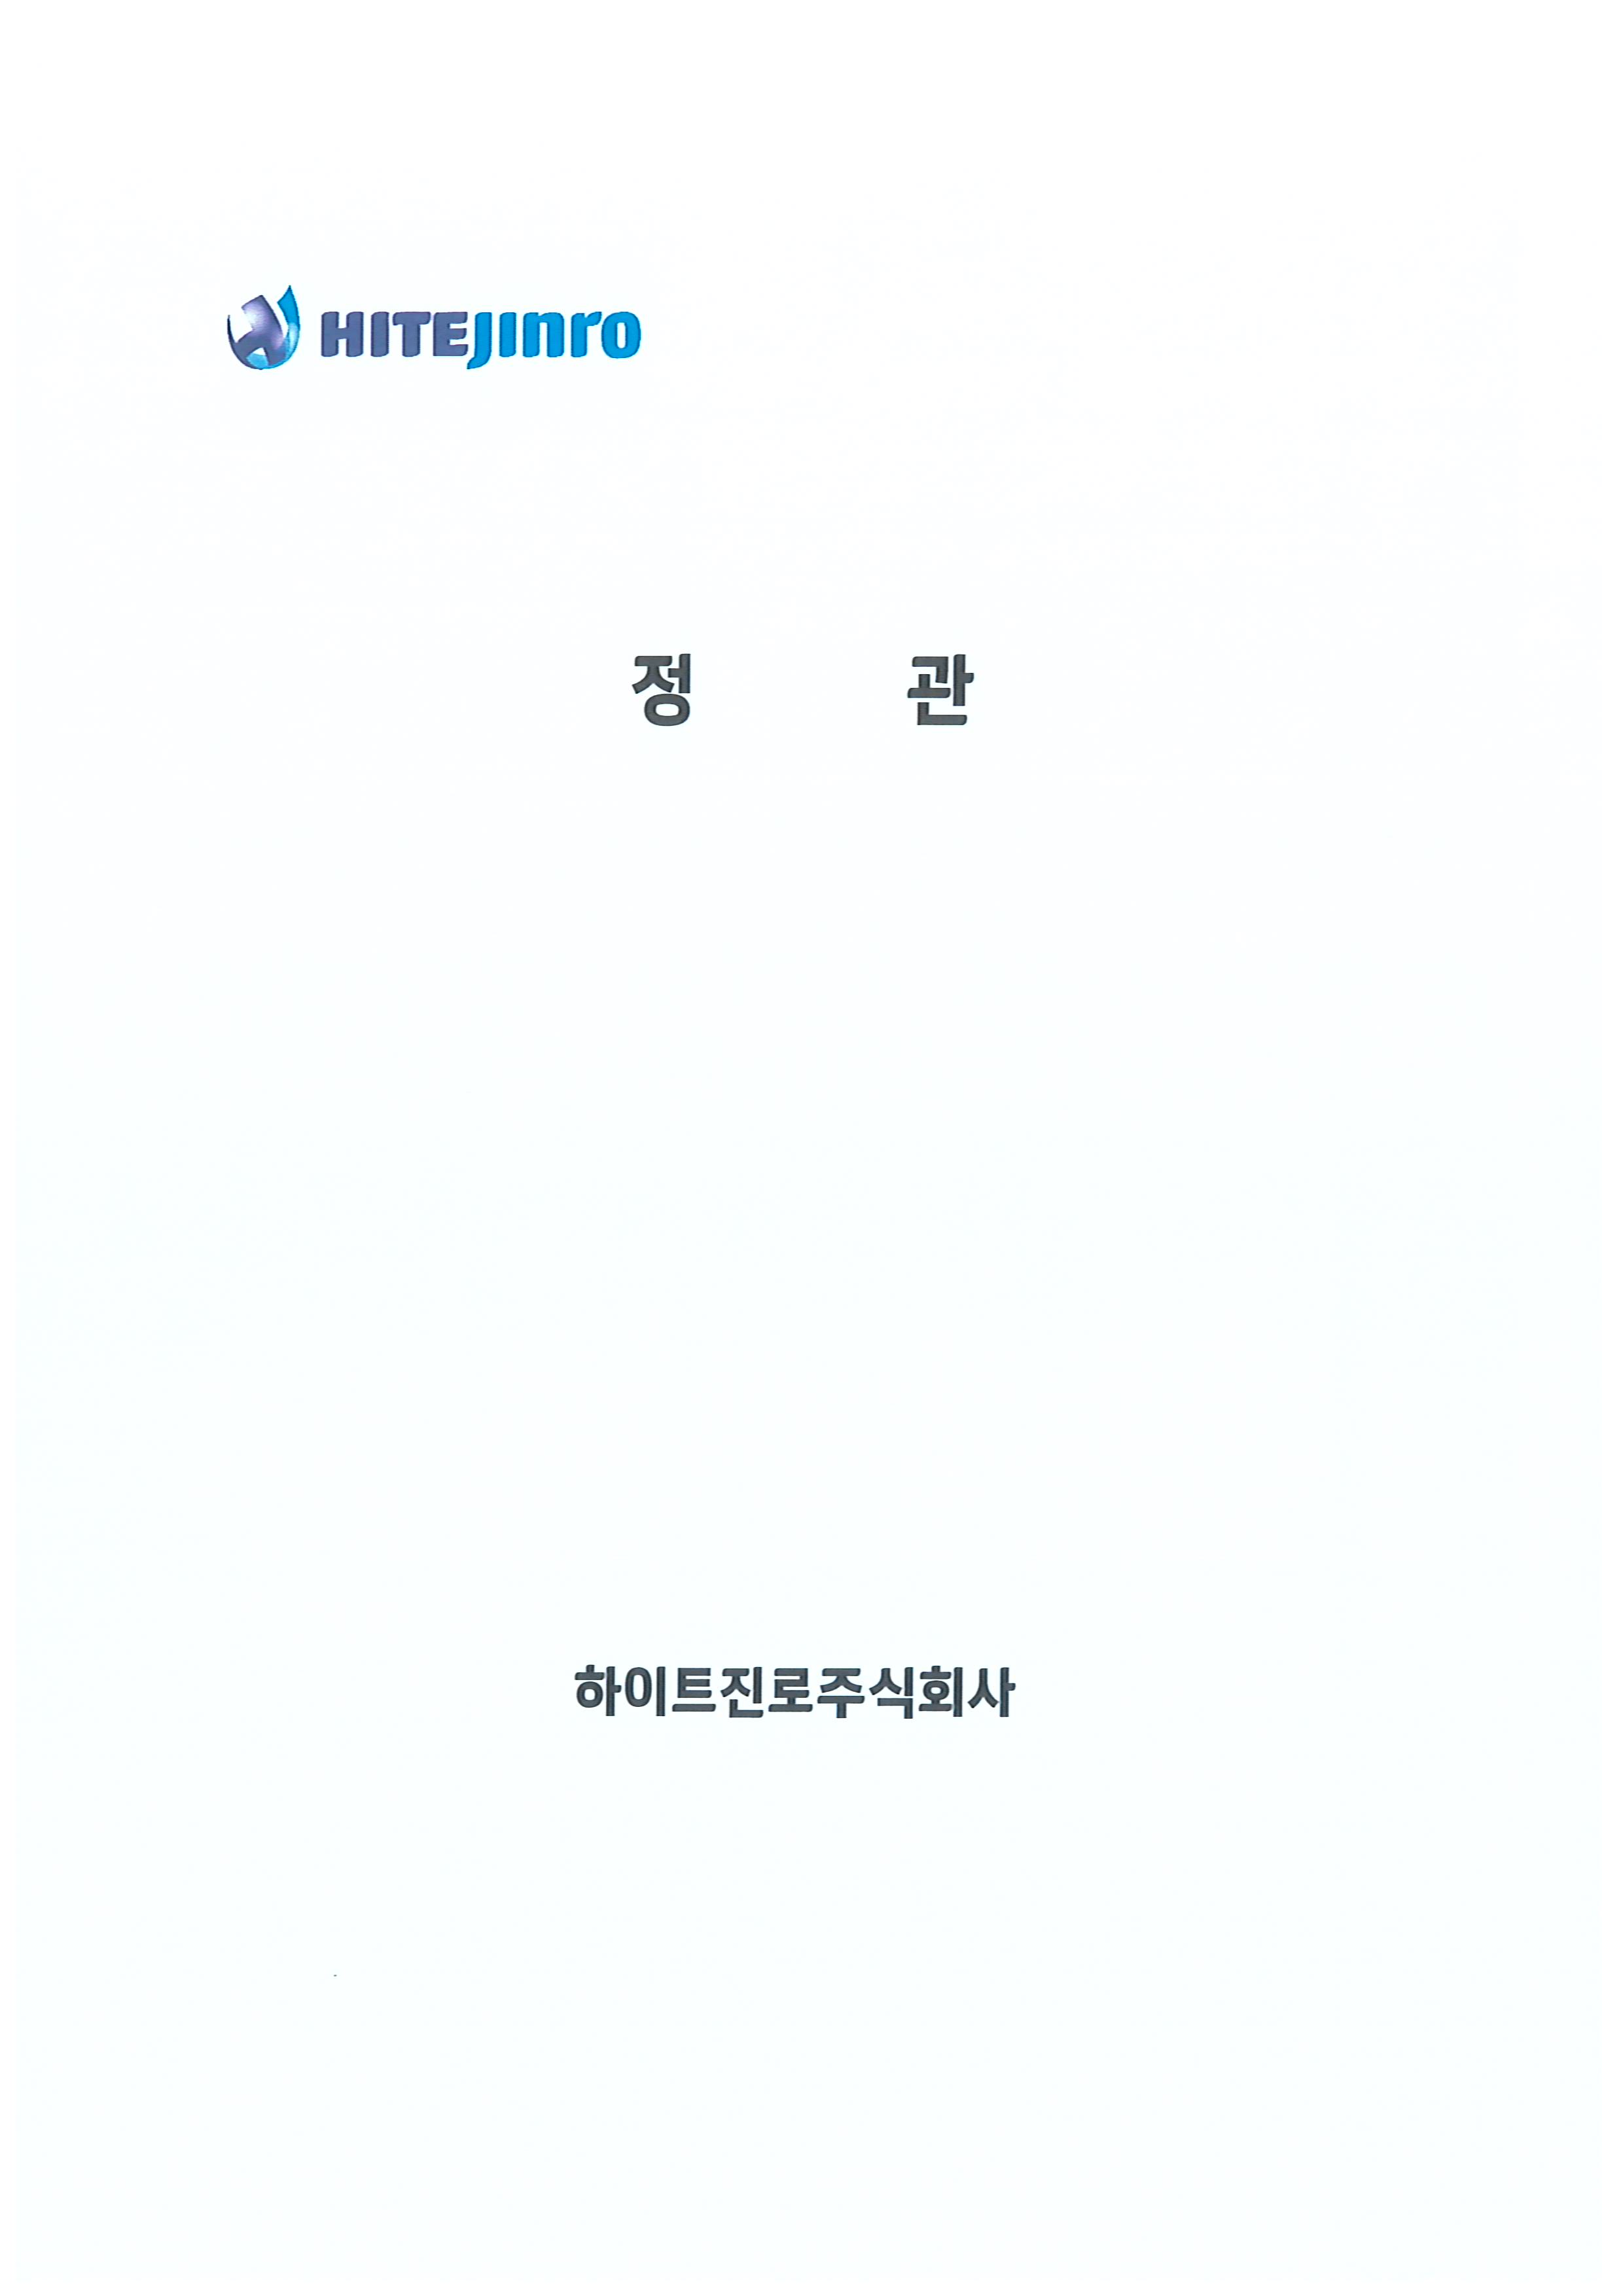

In [8]:
# 텍스트형 하나, 이미지형 하나 보기
from IPython.display import Image, display
t = docs[docs.content_type == "text"].iloc[0]
print(t.corp_name, t.folder); print((ROOT / t.folder / "charter.txt").read_text(encoding="utf-8")[:600])
im = docs[docs.content_type == "image"]
if len(im):
    x = im.iloc[0]; print(x.corp_name, x.folder)
    print((ROOT / x.folder / "charter.txt").read_text(encoding="utf-8")[:300])
    first = ROOT / x.folder / x.images[0]["file"]
    if first.exists():
        display(Image(filename=str(first), width=360))

## 4b. 스캔 정관 글자 인식 (s04b)

`content_type` 이 `image`·`mixed` 인 정관을 Windows 내장 OCR(`ko`)로 읽어 같은 폴더에 `charter_ocr.txt`·`ocr.json` 을 만든다.
Windows 에서만 되고 네트워크는 쓰지 않는다. 이미지 sha256 이 같으면 다시 하지 않는다(`--force` 로 다시). 품질은 docs/01 R5-7.

In [9]:
import subprocess
r = subprocess.run([sys.executable, "-X", "utf8", str(ROOT / "scripts" / "s04b_charter_ocr.py")], capture_output=True, text=True, encoding="utf-8")
print(r.stdout[-1200:] or r.stderr[-1200:])
ocr = C.read_json(C.INTERIM / "s04b_ocr.json")
print("글자 인식 문서", len(ocr), "· 장", sum(v["pages"] for v in ocr.values()), "· 글자", sum(v["total_chars"] for v in ocr.values()))

meta.json 825개 (읽기 실패 0) · OCR 대상(image/mixed) 165개 · 할 일 1개 · 이미 끝남 164개
  1/1 145270_케이탑리츠/20260312_11116296 image 쪽 22 글자 12,786 원문자 121 실패 1 3.86초
끝 — 이번에 OCR 한 문서 1개 · 쪽 22 · 글자 12,786 · 원문자 121 · 실패 쪽 1 · 걸린 시간 5초 (쪽당 벽시계 0.22초, 쪽당 처리 0.49초 × 동시 3)
  색인 data/interim/s04b_ocr.json — 문서 165개 · 쪽 3186 · 글자 2,135,179 · 실패 쪽 1 · 아직 안 한 문서 0개

글자 인식 문서 165 · 장 3186 · 글자 2135179


## 4c. PDF 로 첨부된 정관 (s04c)

원문 화면이 PDF 링크뿐인 정관(처음에는 '빈 문서'로 나온 31개)의 PDF 를 받아(DART 웹) PyMuPDF 로 글자층을 뽑는다.
글자층이 없는 쪽만 s04b 와 같은 글자 인식을 한다 → `charter_pdf.txt`·`pdf.json`. 규칙은 docs/01 R5-8.

In [10]:
import s04c_charter_pdf
s04c_charter_pdf.main()
pdfi = C.read_json(C.INTERIM / "s04c_pdf.json")
print("PDF 정관", len(pdfi), "· 쪽", sum(v["pages"] for v in pdfi.values()), "(글자 인식", sum(v["ocr_pages"] for v in pdfi.values()), ") · 글자", sum(v["total_chars"] for v in pdfi.values()))

PDF 첨부 정관 31개


PDF 정관 31개 · 쪽 583 (OCR 40) · 글자 393,045
PDF 정관 31 · 쪽 583 (글자 인식 40 ) · 글자 393045


## 4d. 스캔 쪽 Opus 전사 (s04d)

스캔 이미지와 PDF 스캔 쪽을 Claude Opus 5.5 가 직접 읽어 `charter_llm.txt` 로 옮긴다(Message Batches API).
**요청을 보내면 비용이 든다** — 아래 `RUN_LLM_SUBMIT` 이 False 면 이미 받은 결과만 정리한다. 키는 `.env` 의 `ANTHROPIC_API_KEY`.
배치를 새로 보냈다면 끝난 뒤(보통 1시간 안) `collect` 를 다시 돌린다. 규칙은 docs/01 R5-9.

In [11]:
import s04d_charter_llm_ocr as s04d
RUN_LLM_SUBMIT = False          # True: 결과가 없는 쪽을 배치로 보낸다 (비용 발생)
if RUN_LLM_SUBMIT:
    s04d.cmd_submit()
s04d.organize()                 # 받은 결과 → charter_llm.txt (네트워크 없음)
llm = C.read_json(C.INTERIM / "s04d_llm.json") if (C.INTERIM / "s04d_llm.json").exists() else {}
print("Opus 전사 문서", len(llm), "· 쪽", sum(v["pages"] for v in llm.values()), "· 글자", sum(v["total_chars"] for v in llm.values()), "· 실패 쪽", sum(v["errors"] for v in llm.values()))

정리: 문서 181개 · 쪽 3,225 · 글자 2,179,464 · 실패 쪽 0 · 누적 토큰 입력 11,381,084 · 출력 2,799,653
Opus 전사 문서 181 · 쪽 3225 · 글자 2179464 · 실패 쪽 0


## 5. 주주총회 소집공고 목록 (s05)

코스피 행마다 **사업보고서 원본 최초 접수일 ~ 기준일**에 **접수된** 주주총회소집공고 최종본(`E006`, `last_reprt_at=Y`)을 센다.
* 원본 최초 접수일 = 목록 행이 정정본이면 DART `family` 의 가장 오래된 본문 접수번호의 날짜 (s03 화면)
* 시장 전체 목록을 3개월 구간으로 한 번에 받고 코스피 회사만 거른다

> 보통 소집공고(주총 2주 전)가 사업보고서(주총 1주 전)보다 먼저 접수되므로, 사업보고서 직후 열리는 정기주총은 이 셈에 들어가지 않을 수 있다.
> 사용자 결정(2026-11-16)으로 **소집공고 접수일 기준**을 쓴다.

In [12]:
import s05_agm_list
s05_agm_list.main()
amap = C.read_json(C.INTERIM / "s05_agm_map.json")
pd.Series({k: len(v["notices"]) for k, v in amap.items()}).value_counts().sort_index()

코스피 825행 · 소집공고 조회 2025-12-15 ~ 2026-11-16
  2025-12-15 ~ 2026-03-14: 2248건


  2026-03-15 ~ 2026-06-14: 884건


  2026-06-15 ~ 2026-09-14: 435건


  2026-09-15 ~ 2026-11-16: 234건


시장 전체 3801건 → 코스피 회사 1046건
  보고서명: [('주주총회소집공고', 794), ('[기재정정]주주총회소집공고', 252)]
원본 제출일 ~ 기준일 안 소집공고: 247건 · 행별 개수 분포 {0: 619, 1: 177, 2: 21, 3: 5, 4: 2, 5: 1} · 원본≠목록행 169행


0    619
1    177
2     21
3      5
4      2
5      1
Name: count, dtype: int64

## 6. 소집공고 XML 원문 → '정관의 변경' 절 (s06)

* 원문: OpenDART `document.xml` ZIP 을 풀어 `data/agm/{종목코드}_{회사명}/{접수일}_{rcept_no}/` 에 그대로 저장
* 찾기: `III. 경영참고사항 › 2. 주주총회 목적사항별 기재사항` 의 안건유형 절 제목 `TITLE@AASSOCNOTE="L0-0-2-2-0"`
  (증권발행공시규정 제3-15조③ 2호 '정관의 변경' — `agm-comparison` 케이스에서 20개 호 전부 실물 확인). 코드가 없으면 '목적사항별 기재사항' 뒤 제목 글자로 찾는다
* 절 = 그 제목의 부모 SECTION 전체 → 같은 폴더 `정관의변경.txt` (표는 행마다 ` | `)

In [13]:
import s06_agm_xml
s06_agm_xml.main()
adocs = pd.DataFrame(C.read_json(C.INTERIM / "s06_agm_docs.json").values())
print(adocs.get("detect", pd.Series(dtype=str)).fillna("-").replace("", "-").value_counts().to_string())
x = adocs[adocs.get("has_charter_amend", False) == True].head(1)
if len(x):
    print(x.iloc[0].corp_name, x.iloc[0].charter_amend_txt)
    print((ROOT / x.iloc[0].charter_amend_txt).read_text(encoding="utf-8")[:800])

소집공고 원문 247건


원문 247/247 · 정관의 변경 있음 146 · 찾은 방법 {'code': 146, '-': 101} · 주총 구분 {'정기': 78, '임시': 169}
  절 글자 수 0~199: 3
detect
code    146
-       101
송원산업 data/agm/004430_송원산업/20260304_20260304000926/정관의변경.txt
□ 정관의 변경
가. 집중투표 배제를 위한 정관의 변경 또는 그 배제된 정관의 변경
변경전 내용 | 변경후 내용 | 변경의 목적
- | - | -

나. 그 외의 정관변경에 관한 건
변경전 내용 | 변경후 내용 | 변경의 목적
제 19 조 (소집지) 주주총회는 본점소재지 또는 이의 인접지 이외에 서울특별시에서도 개최할 수 있다. | 제 19 조 (소집지) ①② 회사는 총회일에 주주가 소집지에 직접 출석하는 방식으로 총회를 개최한다 / 상법 개정에 따른 개정
제 25 조 (의결권의 대리행사) ① 주주는 대리인으로 하여금 그 의결권을 행사하게 할 수 있다. / ② 제1항의 대리인은 주주총회 개시 전에 그 대리권을 증명하는 서면(위임장)을 제출하여야 한다. | 제 25 조 (의결권의 대리행사) ① / ② 제1항의 대리인은 주주총회 개시 전에 그 대리권을 증명하는 서면 또는 전자문서를 제출하여야 한다. / 상법 개정에 따른 개정
제 28 조 (이사의 수) ① 이 회사의 이사는 3명 이상 7명 이내로 하고, 사외이사는 이사 총수의 4분의 1 이상으로 한다. / ② 사외이사의 사임ㆍ사망 등의 사유로 인하여 사외이사의 수가 제1항에서 정한 이사회의 구성요건에 미달하게 되면 그 사유가 발생한 후 처음으로 소집되는 주주총회에서 그 요건에 합치되도록 사외이사를 선임하여야 한다. | 제 28 조 (이사의 수) ① 이 회사의 이사는 3명 이상 7명 이내로 하고, 독립이사는 이사 총수의 3분의 1 이상으로 한다. / ② 독립이사의 사임ㆍ사망 등의 사유로 인하여 독립이사의 수가 제1항에서 정한 이사회의 구성요건에 미달하게 되면 그 사


## 7. 결과물 (s07)

In [14]:
import s07_build
s07_build.main()
final = pd.read_json(C.FINAL / "annual_reports.json", dtype=False)
kc = pd.read_json(C.FINAL / "kospi_charter.json", dtype=False)
print(final.shape, kc.shape)
kc[["corp_name", "report_nm", "rcept_no", "rcept_no_new", "fiscal_year", "settle_month", "market",
    "charter_title", "charter_content_type", "charter_txt", "orig_rcept_dt", "agm_count", "agm_charter_amend_count",
    "agm_charter_amend_txt"]].head(10)

  annual_reports: 3349
  market: {'코스닥': 1784, '코스피': 825, '기타': 633, '코넥스': 107}
  amend_tag: {'(없음)': 2666, '[기재정정]': 536, '[첨부추가]': 61, '[첨부정정]': 86}
  fiscal_year: {'2025': 3284, '2026': 65}
  settle_month: {'2': 3, '3': 26, '4': 4, '5': 4, '6': 23, '7': 3, '8': 3, '9': 5, '11': 2, '12': 3276}
  rcept_no_new_changed: 86
  kospi_rows: 825
  kospi_absent: 4
  kospi_charter_status: {'ok': 825}
  charter_docs: 825
  charter_content_type: {'text': 629, 'image': 164, 'pdf': 31, 'mixed': 1}
  charter_images: 3186
  charter_ocr_docs: 165
  charter_pdf_docs: 31
  charter_llm_docs: 181
  agm_notices: 247
  agm_notices_with_charter_amend: 146
  agm_notice_errors: 0
  kospi_rows_agm_count: {'0': 619, '1': 177, '2': 21, '3': 5, '4': 2, '5': 1}
  kospi_rows_agm_charter_amend_count: {'0': 691, '1': 122, '2': 12}
링크 파일 확인: 없는 경로 0건
(3349, 20) (825, 53)


,corp_name,report_nm,rcept_no,rcept_no_new,fiscal_year,settle_month,market,charter_title,charter_content_type,charter_txt,orig_rcept_dt,agm_count,agm_charter_amend_count,agm_charter_amend_txt
0,금비,사업보고서 (2025.09),20251215000379,20251215000379,2025,9,코스피,2025.12.15 정관,text,data/charter/008870_금비/20251215_10924444/charter.txt,20251215,0,0,[]
1,방림,사업보고서 (2025.09),20251222000124,20251222000124,2025,9,코스피,2025.12.22 정관,text,data/charter/003610_방림/20251222_10934829/charter.txt,20251222,0,0,[]
2,현대약품,사업보고서 (2025.11),20260213002543,20260213002543,2025,11,코스피,2026.02.13 정관,text,data/charter/004310_현대약품/20260213_11027161/charter.txt,20260213,0,0,[]
3,SNT다이내믹스,사업보고서 (2025.12),20260219002133,20260219002133,2025,12,코스피,2026.02.19 정관,text,data/charter/003570_SNT다이내믹스/20260219_11030992/charter.txt,20260219,0,0,[]
4,SNT모티브,사업보고서 (2025.12),20260219002256,20260219002256,2025,12,코스피,2026.02.19 정관,text,data/charter/064960_SNT모티브/20260219_11031216/charter.txt,20260219,1,0,[]
5,SNT에너지,[기재정정]사업보고서 (2025.12),20260220002472,20260220002472,2025,12,코스피,2026.02.19 정관,text,data/charter/100840_SNT에너지/20260219_11031674/charter.txt,20260219,0,0,[]
6,진양폴리우레탄,사업보고서 (2025.12),20260227008561,20260227008561,2025,12,코스피,2026.02.27 정관,text,data/charter/010640_진양폴리우레탄/20260227_11080587/charter.txt,20260227,0,0,[]
7,진양화학,사업보고서 (2025.12),20260303003003,20260303003003,2025,12,코스피,2026.03.03 정관,text,data/charter/051630_진양화학/20260303_11086017/charter.txt,20260303,0,0,[]
8,진양산업,사업보고서 (2025.12),20260304001741,20260304001741,2025,12,코스피,2026.03.05 정관,text,data/charter/003780_진양산업/20260305_11090786/charter.txt,20260304,0,0,[]
9,인천도시가스,사업보고서 (2025.12),20260305001037,20260305001037,2025,12,코스피,2026.03.05 정관,text,data/charter/034590_인천도시가스/20260305_11093237/charter.txt,20260305,0,0,[]


In [15]:
json.loads((C.FINAL / "manifest.json").read_text(encoding="utf-8"))["counts"]

{'annual_reports': 3349,
 'market': {'코스닥': 1784, '코스피': 825, '기타': 633, '코넥스': 107},
 'amend_tag': {'(없음)': 2666, '[기재정정]': 536, '[첨부추가]': 61, '[첨부정정]': 86},
 'fiscal_year': {'2025': 3284, '2026': 65},
 'settle_month': {'2': 3,
  '3': 26,
  '4': 4,
  '5': 4,
  '6': 23,
  '7': 3,
  '8': 3,
  '9': 5,
  '11': 2,
  '12': 3276},
 'rcept_no_new_changed': 86,
 'kospi_rows': 825,
 'kospi_absent': 4,
 'kospi_charter_status': {'ok': 825},
 'charter_docs': 825,
 'charter_content_type': {'text': 629, 'image': 164, 'pdf': 31, 'mixed': 1},
 'charter_images': 3186,
 'charter_ocr_docs': 165,
 'charter_pdf_docs': 31,
 'charter_llm_docs': 181,
 'agm_notices': 247,
 'agm_notices_with_charter_amend': 146,
 'agm_notice_errors': 0,
 'kospi_rows_agm_count': {'0': 619, '1': 177, '2': 21, '3': 5, '4': 2, '5': 1},
 'kospi_rows_agm_charter_amend_count': {'0': 691, '1': 122, '2': 12}}

## 8. 검증

In [16]:
# (1) 목록 — 최종본·중복·접두어
assert final["rcept_no"].is_unique
assert final["report_nm"].str.contains(r"사업보고서 \(\d{4}\.\d{2}\)$").all()
assert (final.loc[~final.amend_tag.str.contains("첨부정정", regex=False), "rcept_no_new"]
        == final.loc[~final.amend_tag.str.contains("첨부정정", regex=False), "rcept_no"]).all()
# (2) 첨부정정 — rcept_no_new 는 family 목록 안의 본문이고 원 접수번호와 다르다
for r in ac.itertuples():
    fam = [f["rcpNo"] for f in pages[r.rcept_no]["family"]]
    assert r.rcept_no_new in fam and r.rcept_no_new != r.rcept_no, r
# (3) 코스피 행 수 = s02 코스피 수, 링크 파일이 실제로 있다
assert len(kc) == (final.market == "코스피").sum()
ok = kc[kc.charter_status == "ok"]
missing = [p for col in ("charter_txt", "charter_meta") for p in ok[col].dropna() if not (ROOT / p).exists()]
print("코스피", len(kc), "· 정관 ok", len(ok), "· 없는 링크", len(missing)); assert not missing
# (4) 이미지 — meta 의 개수·sha256 이 디스크 파일과 같다
import hashlib
bad = unserved = 0
for d in C.read_json(C.INTERIM / "s04_docs.json").values():
    for im in d["images"]:
        if "error" in im:                       # DART 가 서비스하지 않는 이미지 등 — meta 에 이유가 남아 있다
            unserved += 1
            continue
        p = ROOT / d["folder"] / im["file"]
        if not p.exists() or hashlib.sha256(p.read_bytes()).hexdigest() != im.get("sha256"):
            bad += 1
print("이미지 불일치", bad, "· 받지 못한 이미지(이유 기록)", unserved)
assert bad == 0
print(kc.charter_status.value_counts().to_string())
# (5) 회사별 1건
assert final["corp_code"].is_unique
# (6) 주총 — 정관변경 수 ≤ 주총 수, 소집공고 접수일이 기간 안, txt 가 실제로 있다
notices = pd.read_json(C.FINAL / "agm_notices.json", dtype=False)
dt = dict(zip(notices.rcept_no, notices.rcept_dt))
for r in kc.itertuples():
    assert r.agm_charter_amend_count <= r.agm_count == len(r.agm_rcept_nos)
    assert all(r.orig_rcept_dt <= dt[n] <= C.AS_OF.strftime("%Y%m%d") for n in r.agm_rcept_nos), r.rcept_no
    assert all((ROOT / p).exists() for p in r.agm_charter_amend_txt), r.rcept_no
print("소집공고", len(notices), "· 정관변경 포함", int(notices.has_charter_amend.fillna(False).sum()),
      "· 원문 오류", int(notices.error.notna().sum()))
# (6b) KIND 코스피 회사 = 코스피 행 + 목록에 없는 회사, 빠진 회사는 조회기간 사업보고서 0건(수집 누락 없음)
ab = pd.read_json(C.FINAL / "kospi_absent.json", dtype=False)
kk = json.loads((C.FINAL / "manifest.json").read_text(encoding="utf-8"))["kind_kospi"]["detail"]
assert kk["companies"] == len(kc) + len(ab) and not set(ab.stock_code) & set(kc.stock_code)
assert (ab.n_annual_reports_window == 0).all() and "report_in_window" not in set(ab.reason_code)
print(f"KIND 코스피 {kk['companies']}사 = 목록 {len(kc)} + 없음 {len(ab)}", ab.reason_code.value_counts().to_dict())

코스피 825 · 정관 ok 825 · 없는 링크 0


이미지 불일치 0 · 받지 못한 이미지(이유 기록) 1
charter_status
ok    825
소집공고 247 · 정관변경 포함 146 · 원문 오류 0
KIND 코스피 829사 = 목록 825 + 없음 4 {'no_annual_report': 3, 'new_listing': 1}


In [17]:
# (7) attach_docs() 대조 — 이 파이프라인의 첨부문서 파서가 OpenDartReader.attach_docs() 와 같은 목록을 내는지
#     DART 에 직접 요청하므로 기본은 끈다. 확인할 때만 True.
RUN_LIVE_CHECK = False
if RUN_LIVE_CHECK:
    try:
        from opendartreader import OpenDartReader       # 0.3.x
    except ImportError:
        import OpenDartReader                           # 0.2.x (모듈 자체가 클래스)
    dart = OpenDartReader(C.dart_keys()[0])
    sample = list(ok.sample(3, random_state=0).rcept_no) + list(ac.rcept_no[:2])
    for rno in sample:
        lib = dart.attach_docs(rno)
        lib_rows = [(t, u.replace("http://", "https://")) for t, u in zip(lib.title, lib.url)]
        mine = [(a["title"], a["url"]) for a in pages[rno]["att"]]
        print(rno, "일치" if lib_rows == mine else "불일치", len(lib_rows))

## 9. 웹페이지 (s08)

`site/index.html` 은 고정 틀이고 `scripts/s08_site.py` 가 `data/final` 로 `site/data.js` 를 만든다.
본문 미리보기(정관 txt·정관의변경 txt)는 `fetch` 로 읽으므로 케이스 폴더에서 `python -m http.server` 를 띄우고
`http://localhost:8000/site/` 로 연다 (file:// 로 열면 표는 보이고 미리보기 대신 링크가 나온다).

In [18]:
import subprocess
if (ROOT / "scripts" / "s08_site.py").exists():
    print(subprocess.run([sys.executable, "-X", "utf8", str(ROOT / "scripts" / "s08_site.py")],
                         capture_output=True, text=True, encoding="utf-8").stdout[-800:])

C:\Users\Peter\github\case-projects\kospi-charter\site\data.js 2.95MB · kospi_charter 825행 · annual_reports 3,349행 · agm_notices 247행 · charter_docs 825행 · kospi_absent 4행 · 0.2초
  로컬 파일 kospi_charter.charter_txt: 825/825 있음
  로컬 파일 kospi_charter.charter_img_dir: 165/165 있음
  로컬 파일 kospi_charter.agm_charter_amend_txt: 146/146 있음
  로컬 파일 agm_notices.charter_amend_txt: 146/146 있음



## 10. 다시 만들기·갱신

* **같은 기준일로 재현**: 이 노트북을 그대로 실행 (캐시를 읽는다).
* **기준일을 옮겨 새로 받기**: 0번 셀의 `KC_AS_OF` 를 바꾸고 `data/raw/`·`data/interim/`·`data/charter/` 를 지운 뒤 실행.
  DART 화면의 `family`·`att` 는 수집시점 기준이다(`s03_main.json` 의 `fetched_at`, 범위는 `manifest.json` 의 `fetched`).
* 스캔 이미지는 git 에 올리지 않는다(`.gitignore`). `meta.json` 의 `src_url` 로 다시 받을 수 있고 `sha256` 으로 같은 파일인지 확인한다.
